# Lab 3 – Task 5: Monte Carlo Value at Risk (VaR)
**Stock:** IndusInd Bank Ltd. (`INDUSINDBK.NS`, NSE)

This section estimates **one-day VaR at 90%, 95% and 99%** by Monte Carlo simulation, using the model

$$
R_{t+1}=\mu_d+\sigma_d Z
$$

where $\mu_d$ and $\sigma_d$ are the **daily** mean and standard deviation of the **most recent 200 daily simple returns**, and $Z$ is a random draw from a **standardised** (mean 0, variance 1) probability distribution.

**Conventions (same as the sample notebook):** simple daily returns in decimal form, daily (not annualised) volatility, VaR reported as a **positive loss**, e.g. 0.025 = a 2.5% loss.

**Plan of this section**
1. Setup, data and the 200-day VaR sample
2. Historical parameters $\mu_d,\sigma_d$ and a look at the return distribution
3. Choice and parameterisation of the distribution for $Z$
4. Simulation (10,000+ draws) and Monte Carlo VaR
5. Comparison with Historical and Parametric VaR
6. Robustness: degrees of freedom, simulation error
7. Report-ready summary, justification, advantages and limitations

## 1. Setup and data

In [1]:
%pip install numpy pandas matplotlib scipy yfinance -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

# ---------- inputs ----------
ticker     = "INDUSINDBK.NS"
start_date = "2020-06-01"      # long sample (Task 2); only the last 200 returns are used for VaR
end_date   = "2026-11-14"      # yfinance treats the end date as exclusive

var_window = 200                       # most recent 200 trading days of returns
conf_levels = [0.90, 0.95, 0.99]
n_sims     = 100_000                   # >= 10,000 required
seed       = 42                        # reproducibility

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

In [3]:
data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True, progress=False)

price   = data["Close"].squeeze()
returns = price.pct_change().dropna()          # simple daily returns, decimal form

# --- the 200-day VaR sample (same sample as Tasks 3, 4 and 6) ---
ret200 = returns.iloc[-var_window:]

print(f"Long sample : {returns.index[0].date()} -> {returns.index[-1].date()}  ({len(returns)} returns)")
print(f"VaR sample  : {ret200.index[0].date()} -> {ret200.index[-1].date()}  ({len(ret200)} returns)")
assert len(ret200) == var_window, "Not enough data for a 200-day sample"
assert ret200.isna().sum() == 0

Long sample : 2020-06-02 -> 2026-11-12  (1599 returns)
VaR sample  : 2026-01-20 -> 2026-11-12  (200 returns)


## 2. Historical parameters from the 200-day sample

$$
\mu_d=\frac1n\sum_{i=1}^{n} r_i,\qquad
\sigma_d=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(r_i-\mu_d)^2},\qquad n=200
$$

The sample standard deviation (denominator $n-1$) is used, consistent with the pandas `.std()` calls in the sample notebook. Before choosing a distribution for $Z$, we check whether the 200 returns look normal: skewness, excess kurtosis, the Jarque–Bera test and a Q–Q plot.

In [4]:
mu_d    = ret200.mean()
sigma_d = ret200.std(ddof=1)

skew      = stats.skew(ret200, bias=False)
ex_kurt   = stats.kurtosis(ret200, fisher=True, bias=False)   # excess kurtosis (normal = 0)
jb_stat, jb_p = stats.jarque_bera(ret200)

params = pd.Series({
    "n (observations)"        : len(ret200),
    "Mean return mu_d"        : mu_d,
    "Daily volatility sigma_d": sigma_d,
    "Minimum daily return"    : ret200.min(),
    "Maximum daily return"    : ret200.max(),
    "Skewness"                : skew,
    "Excess kurtosis"         : ex_kurt,
    "Jarque-Bera statistic"   : jb_stat,
    "Jarque-Bera p-value"     : jb_p,
})
params

n (observations)           200.000000
Mean return mu_d             0.000106
Daily volatility sigma_d     0.019820
Minimum daily return        -0.059665
Maximum daily return         0.065176
Skewness                    -0.006206
Excess kurtosis              1.046312
Jarque-Bera statistic        8.176783
Jarque-Bera p-value          0.016766
dtype: float64

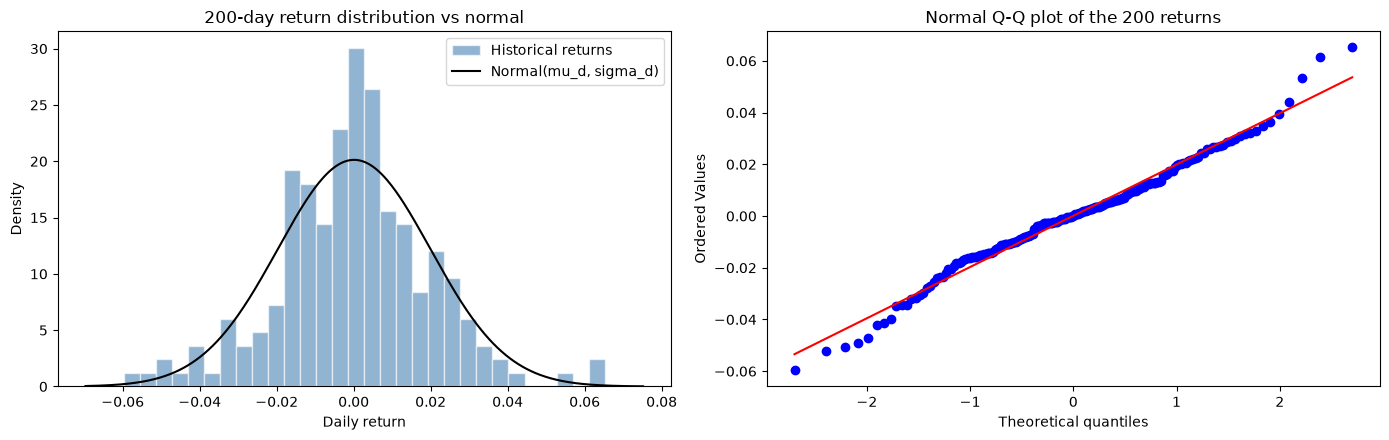

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# histogram vs fitted normal
ax[0].hist(ret200, bins=30, density=True, alpha=0.6, color="steelblue", edgecolor="white", label="Historical returns")
xs = np.linspace(ret200.min() - 0.01, ret200.max() + 0.01, 400)
ax[0].plot(xs, stats.norm.pdf(xs, mu_d, sigma_d), "k", lw=1.5, label="Normal(mu_d, sigma_d)")
ax[0].set_title("200-day return distribution vs normal")
ax[0].set_xlabel("Daily return"); ax[0].set_ylabel("Density"); ax[0].legend()

# Q-Q plot vs normal
stats.probplot(ret200, dist="norm", plot=ax[1])
ax[1].set_title("Normal Q-Q plot of the 200 returns")
plt.tight_layout(); plt.show()

## 3. Choice of distribution for $Z$ and its parameterisation

**Choice: Student-t distribution.** Daily bank-stock returns are typically **fat-tailed** (positive excess kurtosis): extreme days occur more often than a normal distribution allows. A Student-t with a small number of degrees of freedom $\nu$ captures this. The normal distribution is also simulated below as a benchmark, so the effect of the distributional assumption can be isolated.

**Appropriate parameterisation (important).** A raw Student-t variable $T_\nu$ has variance $\nu/(\nu-2)$ (for $\nu>2$), not 1. If $T_\nu$ were plugged directly into $R=\mu_d+\sigma_dZ$, the simulated volatility would be *larger* than the $\sigma_d$ estimated from the data. The model therefore uses the **standardised** t variable

$$
Z=\frac{T_\nu}{\sqrt{\nu/(\nu-2)}},\qquad E[Z]=0,\quad \mathrm{Var}[Z]=1,
$$

so that $\mu_d$ and $\sigma_d$ really are the mean and standard deviation of the simulated returns, and only the **shape** (tail heaviness) is governed by $\nu$.

**Estimating $\nu$.** Two estimates are computed from the 200 returns:
- *Maximum likelihood* fit of a location-scale Student-t (`scipy.stats.t.fit`).
- *Method of moments* from excess kurtosis, using $\text{excess kurtosis}=\dfrac{6}{\nu-4}$ for $\nu>4$, i.e. $\nu=4+6/\text{excess kurtosis}$.

The MLE is used as the main estimate. Since $\nu$ must exceed 2 for the variance to exist (and is poorly identified with only 200 points), it is restricted to the range **[3, 30]**; above about 30 the t is practically indistinguishable from the normal. Section 6 shows how sensitive VaR is to this choice.

In [6]:
# --- maximum likelihood estimate of nu (fit on returns in %, for numerical stability) ---
nu_mle, loc_mle, scale_mle = stats.t.fit(ret200 * 100)

# --- method-of-moments estimate from excess kurtosis (needs excess kurtosis > 0) ---
nu_mom = 4 + 6 / ex_kurt if ex_kurt > 0 else np.inf

nu_lo, nu_hi = 3.0, 30.0
nu = float(np.clip(nu_mle, nu_lo, nu_hi))

print(f"nu (MLE)                  : {nu_mle:8.2f}")
print(f"nu (kurtosis, moments)    : {nu_mom:8.2f}")
print(f"nu USED in the simulation : {nu:8.2f}", end="")
print("   <- MLE value was clipped to [3, 30]" if nu != nu_mle else "")

# standardisation constant: Var(T_nu) = nu/(nu-2)
t_std_const = np.sqrt(nu / (nu - 2))
print(f"Var(T_nu) = {nu/(nu-2):.4f}  -> divide draws by {t_std_const:.4f} so that Var(Z) = 1")

nu (MLE)                  :     5.61
nu (kurtosis, moments)    :     9.73
nu USED in the simulation :     5.61
Var(T_nu) = 1.5541  -> divide draws by 1.2466 so that Var(Z) = 1


## 4. Monte Carlo simulation and VaR

**Procedure**
1. $\mu_d,\sigma_d$ from the 200 historical returns (Section 2).
2. $Z$ = standardised Student-t($\nu$) (Section 3).
3. Generate `n_sims` = 100,000 simulated next-day returns $R_{t+1}=\mu_d+\sigma_dZ$ (the lab requires at least 10,000; more draws reduce simulation noise in the 1% tail).
4. VaR = minus the 10th, 5th and 1st percentile of the simulated returns (positive loss).

A fixed random seed makes the results reproducible.

In [7]:
def draw_Z(dist, n, rng, nu=None):
    """Standardised draws (mean 0, variance 1)."""
    if dist == "t":
        return rng.standard_t(nu, size=n) / np.sqrt(nu / (nu - 2))
    if dist == "normal":
        return rng.standard_normal(n)
    raise ValueError(dist)

def mc_var(mu, sigma, dist, n, rng, nu=None, conf=conf_levels):
    """Simulate R = mu + sigma*Z and return (VaR dict as positive losses, simulated returns)."""
    sim = mu + sigma * draw_Z(dist, n, rng, nu)
    var = {c: -np.percentile(sim, 100 * (1 - c)) for c in conf}
    return var, sim

rng = np.random.default_rng(seed)
var_t, sim_t = mc_var(mu_d, sigma_d, "t", n_sims, rng, nu=nu)

rng = np.random.default_rng(seed)
var_n, sim_n = mc_var(mu_d, sigma_d, "normal", n_sims, rng)

# sanity checks: the simulated sample must reproduce the target mean / std
print(f"Student-t sim : mean = {sim_t.mean():.6f} (target {mu_d:.6f}),  std = {sim_t.std(ddof=1):.6f} (target {sigma_d:.6f}),  "
      f"excess kurtosis = {stats.kurtosis(sim_t):.2f}")
print(f"Normal sim    : mean = {sim_n.mean():.6f},  std = {sim_n.std(ddof=1):.6f},  excess kurtosis = {stats.kurtosis(sim_n):.2f}")

Student-t sim : mean = 0.000081 (target 0.000106),  std = 0.019789 (target 0.019820),  excess kurtosis = 2.98
Normal sim    : mean = 0.000022,  std = 0.019893,  excess kurtosis = 0.02


In [8]:
labels = [f"{int(c*100)}% VaR" for c in conf_levels]
pct    = [f"{int(100*(1-c))}th percentile" if c != 0.99 else "1st percentile" for c in conf_levels]
pct    = ["10th percentile", "5th percentile", "1st percentile"]

mc_table = pd.DataFrame({
    "Confidence level"             : [f"{int(c*100)}%" for c in conf_levels],
    "Percentile used"              : pct,
    "Simulated return at percentile": [-var_t[c] for c in conf_levels],
    "MC VaR (decimal)"             : [var_t[c] for c in conf_levels],
    "MC VaR (% loss)"              : [f"{100*var_t[c]:.3f}%" for c in conf_levels],
}).set_index("Confidence level")

print(f"Monte Carlo VaR - Student-t (nu = {nu:.2f}), {n_sims:,} simulations, mu_d = {mu_d:.6f}, sigma_d = {sigma_d:.6f}")
mc_table

Monte Carlo VaR - Student-t (nu = 5.61), 100,000 simulations, mu_d = 0.000106, sigma_d = 0.019820


,Percentile used,Simulated return at percentile,MC VaR (decimal),MC VaR (% loss)
Confidence level,,,,
90%,10th percentile,-0.022919,0.022919,2.292%
95%,5th percentile,-0.031073,0.031073,3.107%
99%,1st percentile,-0.051301,0.051301,5.130%


## 5. Comparison with Historical and Parametric VaR

To discuss differences from the other methods, the **reference** values below are recomputed from the same 200 returns:

- **Historical simulation:** minus the 10th/5th/1st percentile of the 200 observed returns (Task 3).
- **Parametric (normal), 200-day historical volatility:** $\text{VaR}=z_{c}\,\sigma-\mu$ with $z_c$ the standard normal quantile (Task 4). Here the 200-day window is used for the comparison. If you chose a different window in Task 4, change `hist_window` below and the comparison will use your choice.

Because the parametric normal VaR is the *analytical* counterpart of the normal Monte Carlo, the normal MC should match it up to simulation noise, which is a useful correctness check.

In [9]:
hist_window = 200      # <- change to the window you chose for Task 4 (<= 200)

# Historical simulation (Task 3)
var_hist = {c: -np.percentile(ret200, 100 * (1 - c)) for c in conf_levels}

# Parametric normal, historical volatility (Task 4): VaR = z*sigma - mu
mu_p    = ret200.iloc[-hist_window:].mean()
sigma_p = ret200.iloc[-hist_window:].std(ddof=1)
var_param = {c: stats.norm.ppf(c) * sigma_p - mu_p for c in conf_levels}

comparison = pd.DataFrame(
    {
        "Historical Simulation"               : var_hist,
        f"Parametric - Hist. Vol ({hist_window}d)": var_param,
        "Monte Carlo - Normal (benchmark)"    : var_n,
        f"Monte Carlo - Student-t (nu={nu:.1f})": var_t,
    }
).T
comparison.columns = ["90% VaR", "95% VaR", "99% VaR"]

print("VaR as a positive loss (decimal) and in %:")
display(comparison)
display((comparison * 100).round(3).astype(str) + "%")

VaR as a positive loss (decimal) and in %:


,90% VaR,95% VaR,99% VaR
Historical Simulation,0.023615,0.034440,0.050612
Parametric - Hist. Vol (200d),0.025294,0.032495,0.046002
Monte Carlo - Normal (benchmark),0.025456,0.032762,0.046342
Monte Carlo - Student-t (nu=5.6),0.022919,0.031073,0.051301


,90% VaR,95% VaR,99% VaR
Historical Simulation,2.362%,3.444%,5.061%
Parametric - Hist. Vol (200d),2.529%,3.249%,4.6%
Monte Carlo - Normal (benchmark),2.546%,3.276%,4.634%
Monte Carlo - Student-t (nu=5.6),2.292%,3.107%,5.13%


In [10]:
# correctness check: normal MC vs analytic normal VaR (same mu, sigma -> should agree up to MC noise)
analytic_same_params = {c: stats.norm.ppf(c) * sigma_d - mu_d for c in conf_levels}
chk = pd.DataFrame({"Normal MC": var_n, "Analytic normal": analytic_same_params})
chk["Abs. difference"] = (chk["Normal MC"] - chk["Analytic normal"]).abs()
chk.index = [f"{int(c*100)}%" for c in chk.index]
chk

,Normal MC,Analytic normal,Abs. difference
90%,0.025456,0.025294,0.000161
95%,0.032762,0.032495,0.000267
99%,0.046342,0.046002,0.000340


In [11]:
# data-driven reading of the comparison
print("MC Student-t VaR relative to the other methods (positive = MC higher):\n")
for c in conf_levels:
    for name, ref in [("Historical", var_hist), ("Parametric normal", var_param)]:
        d = var_t[c] - ref[c]
        print(f"  {int(c*100)}% VaR: MC t vs {name:<18}: {100*d:+.3f} pp  ({100*d/ref[c]:+.1f}%)")
    print()

MC Student-t VaR relative to the other methods (positive = MC higher):

  90% VaR: MC t vs Historical        : -0.070 pp  (-2.9%)
  90% VaR: MC t vs Parametric normal : -0.238 pp  (-9.4%)

  95% VaR: MC t vs Historical        : -0.337 pp  (-9.8%)
  95% VaR: MC t vs Parametric normal : -0.142 pp  (-4.4%)

  99% VaR: MC t vs Historical        : +0.069 pp  (+1.4%)
  99% VaR: MC t vs Parametric normal : +0.530 pp  (+11.5%)



## Visualisation of the simulated distribution and its tail

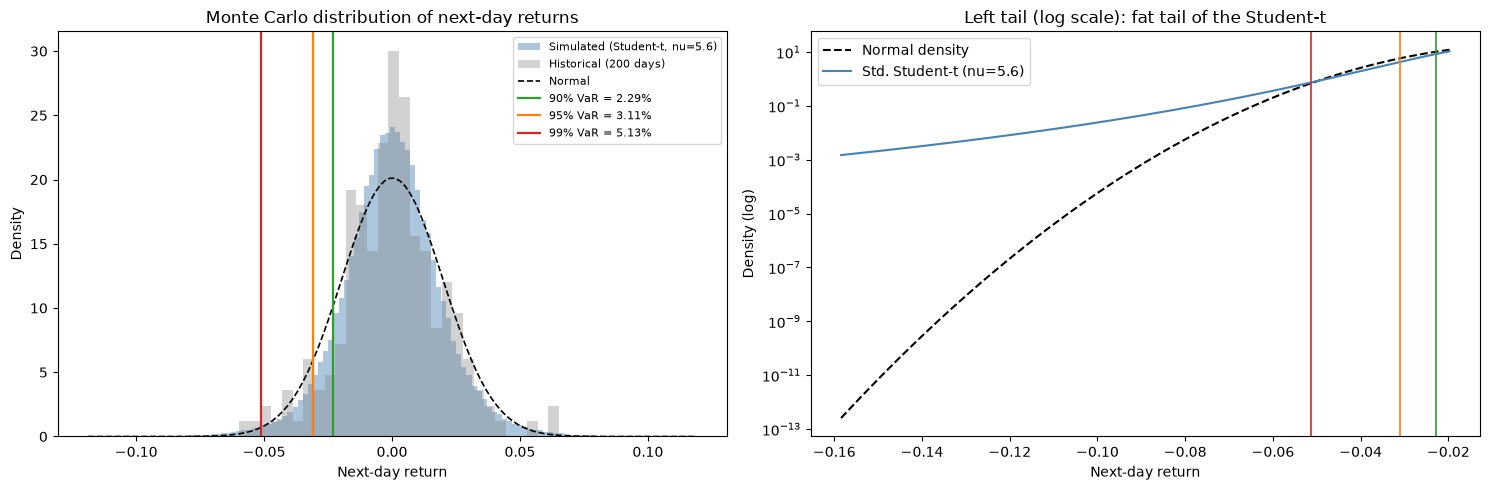

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
colors = {0.90: "tab:green", 0.95: "tab:orange", 0.99: "tab:red"}

# (a) full distribution
bins = np.linspace(-6 * sigma_d + mu_d, 6 * sigma_d + mu_d, 120)
ax[0].hist(sim_t, bins=bins, density=True, alpha=0.45, color="steelblue", label=f"Simulated (Student-t, nu={nu:.1f})")
ax[0].hist(ret200, bins=30, density=True, alpha=0.35, color="grey", label="Historical (200 days)")
ax[0].plot(bins, stats.norm.pdf(bins, mu_d, sigma_d), "k--", lw=1.2, label="Normal")
for c in conf_levels:
    ax[0].axvline(-var_t[c], color=colors[c], lw=1.6, label=f"{int(c*100)}% VaR = {100*var_t[c]:.2f}%")
ax[0].set_title("Monte Carlo distribution of next-day returns")
ax[0].set_xlabel("Next-day return"); ax[0].set_ylabel("Density"); ax[0].legend(fontsize=8)

# (b) left-tail zoom: Student-t vs normal
lo = min(sim_t.min(), sim_n.min())
xt = np.linspace(max(lo, mu_d - 8 * sigma_d), mu_d - 1.0 * sigma_d, 300)
ax[1].plot(xt, stats.norm.pdf(xt, mu_d, sigma_d), "k--", label="Normal density")
z = (xt - mu_d) / sigma_d
ax[1].plot(xt, stats.t.pdf(z * t_std_const, nu) * t_std_const / sigma_d, color="steelblue", label=f"Std. Student-t (nu={nu:.1f})")
for c in conf_levels:
    ax[1].axvline(-var_t[c], color=colors[c], lw=1.2)
ax[1].set_yscale("log")
ax[1].set_title("Left tail (log scale): fat tail of the Student-t")
ax[1].set_xlabel("Next-day return"); ax[1].set_ylabel("Density (log)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Robustness checks

### 6a. Sensitivity of Monte Carlo VaR to the degrees of freedom $\nu$
$\nu$ is estimated from only 200 observations and is therefore uncertain. The table shows VaR for a range of $\nu$ (with the same $\mu_d,\sigma_d$), together with the **theoretical** multiplier $q_c(\nu)$ = the standardised-t quantile, so that $\text{VaR}\approx q_c(\nu)\,\sigma_d-\mu_d$. The normal case ($\nu\to\infty$) is the last row.

In [13]:
nus = [3, 4, 5, 6, 8, 10, 15, 30]
rows = {}
for v in nus:
    rng = np.random.default_rng(seed)
    var_v, _ = mc_var(mu_d, sigma_d, "t", n_sims, rng, nu=v)
    rows[f"t, nu={v}"] = {**{f"MC VaR {int(c*100)}%": var_v[c] for c in conf_levels},
                          **{f"multiplier {int(c*100)}%": stats.t.ppf(c, v) / np.sqrt(v / (v - 2)) for c in conf_levels}}
rows["Normal (nu -> inf)"] = {**{f"MC VaR {int(c*100)}%": var_n[c] for c in conf_levels},
                              **{f"multiplier {int(c*100)}%": stats.norm.ppf(c) for c in conf_levels}}
sens = pd.DataFrame(rows).T
sens

,MC VaR 90%,MC VaR 95%,MC VaR 99%,multiplier 90%,multiplier 95%,multiplier 99%
"t, nu=3",0.018617,0.026891,0.051702,0.945552,1.358715,2.621576
"t, nu=4",0.021290,0.029656,0.052055,1.084141,1.507443,2.649492
"t, nu=5",0.022511,0.030717,0.051331,1.143215,1.560850,2.606464
"t, nu=6",0.023158,0.031291,0.051133,1.175556,1.586600,2.565978
"t, nu=8",0.023847,0.031751,0.049358,1.209678,1.610416,2.508407
"t, nu=10",0.024176,0.031989,0.048332,1.227318,1.621115,2.471991
"t, nu=15",0.024556,0.032240,0.047250,1.248036,1.632001,2.422777
"t, nu=30",0.025020,0.032543,0.046653,1.265981,1.639710,2.373940
Normal (nu -> inf),0.025456,0.032762,0.046342,1.281552,1.644854,2.326348


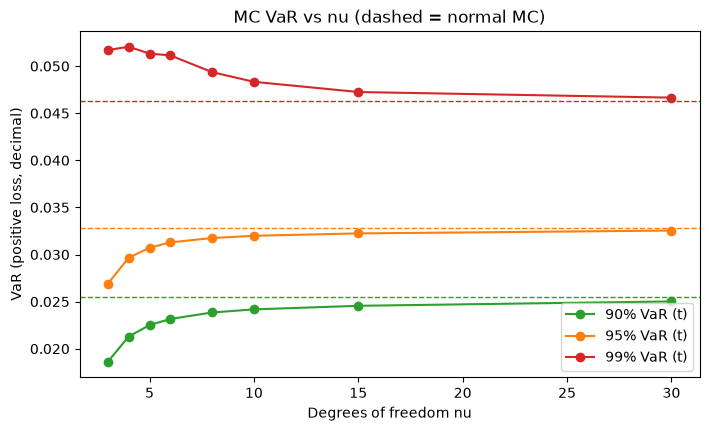

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in conf_levels:
    ax.plot(nus, [rows[f"t, nu={v}"][f"MC VaR {int(c*100)}%"] for v in nus], marker="o", color=colors[c], label=f"{int(c*100)}% VaR (t)")
    ax.axhline(var_n[c], color=colors[c], ls="--", lw=1)
ax.set_xlabel("Degrees of freedom nu"); ax.set_ylabel("VaR (positive loss, decimal)")
ax.set_title("MC VaR vs nu (dashed = normal MC)")
ax.legend(); plt.show()

### 6b. Simulation (sampling) error
Monte Carlo output changes slightly with the random seed. To quantify this, the whole simulation is repeated with 200 different seeds. The spread of the results measures the pure simulation noise (as opposed to the estimation uncertainty in $\mu_d,\sigma_d,\nu$ which is not captured here).

In [15]:
reps = 200
res = np.empty((reps, len(conf_levels)))
for k in range(reps):
    rng = np.random.default_rng(1000 + k)
    v, _ = mc_var(mu_d, sigma_d, "t", n_sims, rng, nu=nu)
    res[k] = [v[c] for c in conf_levels]

stab = pd.DataFrame({
    "Mean VaR"            : res.mean(axis=0),
    "Std. dev. across seeds": res.std(axis=0, ddof=1),
    "Min"                 : res.min(axis=0),
    "Max"                 : res.max(axis=0),
    "Std. dev. as % of VaR": 100 * res.std(axis=0, ddof=1) / res.mean(axis=0),
}, index=[f"{int(c*100)}%" for c in conf_levels])
print(f"{reps} repetitions x {n_sims:,} simulations each")
stab

200 repetitions x 100,000 simulations each


,Mean VaR,Std. dev. across seeds,Min,Max,Std. dev. as % of VaR
90%,0.022991,0.000115,0.022651,0.023276,0.499017
95%,0.031192,0.000172,0.030596,0.031549,0.552233
99%,0.051012,0.000397,0.049957,0.051988,0.778247


In [16]:
# how many simulations are 'enough'? 99% VaR vs. number of draws
sizes = [1_000, 5_000, 10_000, 50_000, 100_000, 500_000]
conv = {}
for n in sizes:
    vals = []
    for k in range(30):
        rng = np.random.default_rng(5000 + k)
        vals.append(mc_var(mu_d, sigma_d, "t", n, rng, nu=nu)[0][0.99])
    conv[n] = (np.mean(vals), np.std(vals, ddof=1))
conv = pd.DataFrame(conv, index=["Mean 99% VaR", "Std. dev. across seeds"]).T
conv.index.name = "Number of simulations"
conv

,Mean 99% VaR,Std. dev. across seeds
Number of simulations,,
1000,0.050662,0.005013
5000,0.051092,0.002203
10000,0.050990,0.001051
50000,0.050918,0.000590
100000,0.050913,0.000464
500000,0.051069,0.000185
